# **Experiment 12: LoRA versus Full Fine-Tuning**

**Aim:**
To compare LoRA-based parameter-efficient fine-tuning with full fine-tuning under a controlled experimental setup.

**Brief Theory:**
Full fine-tuning updates all model parameters, whereas LoRA freezes the pre-trained model and trains only small low-rank adapter matrices. LoRA can significantly reduce the number of trainable parameters, memory requirements and checkpoint size. This experiment compares both methods using the same model, dataset, training schedule and unseen test data.

In [1]:
# Experiment 12: LoRA versus Full Fine-Tuning

!pip install -q transformers peft accelerate datasets

import os
import gc
import json
import time
import math
import random
import torch
import pandas as pd
import matplotlib.pyplot as plt

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling,
    set_seed
)
from peft import LoraConfig, TaskType, get_peft_model

print("Student Name: Sayem")
print("Student ID: 25/SET/MTCE/014")
print("Libraries loaded successfully!")
print("PyTorch:", torch.__version__)

Student Name: Sayem
Student ID: 25/SET/MTCE/014
Libraries loaded successfully!
PyTorch: 2.14.1+cpu


In [2]:
# Create the Custom Dataset
data = [
    {"instruction": "What is Artificial Intelligence?",
     "response": "Artificial Intelligence enables machines to perform tasks that normally require human intelligence."},

    {"instruction": "What is Machine Learning?",
     "response": "Machine Learning allows computers to learn patterns from data and make predictions."},

    {"instruction": "What is Deep Learning?",
     "response": "Deep Learning uses multi-layer neural networks to learn complex patterns from data."},

    {"instruction": "What is Computer Vision?",
     "response": "Computer Vision enables computers to understand and analyze images and videos."},

    {"instruction": "What is Natural Language Processing?",
     "response": "Natural Language Processing enables computers to understand and process human language."},

    {"instruction": "What is Generative AI?",
     "response": "Generative AI creates new content such as text, images, audio and videos."},

    {"instruction": "What is a Neural Network?",
     "response": "A Neural Network is a computational model inspired by the structure of the human brain."},

    {"instruction": "What is Data Science?",
     "response": "Data Science uses statistics, programming and machine learning to extract useful information from data."},

    {"instruction": "What is a Large Language Model?",
     "response": "A Large Language Model is trained on large text datasets to understand and generate human language."},

    {"instruction": "What is Fine-Tuning?",
     "response": "Fine-Tuning adapts a pre-trained model to perform better on a specific task or dataset."},

    {"instruction": "What is an algorithm?",
     "response": "An algorithm is a step-by-step procedure for solving a computational problem."},

    {"instruction": "What is a dataset?",
     "response": "A dataset is an organized collection of information used for analysis and machine learning."},

    {"instruction": "What is classification?",
     "response": "Classification is a machine learning task that assigns input data to predefined categories."},

    {"instruction": "What is regression?",
     "response": "Regression predicts continuous numerical values from input features."},

    {"instruction": "What is tokenization?",
     "response": "Tokenization divides text into smaller units called tokens for language model processing."},

    {"instruction": "What is an encoder?",
     "response": "An encoder transforms input information into a contextual representation."},

    {"instruction": "What is a decoder?",
     "response": "A decoder generates output sequences using encoded information or previous tokens."},

    {"instruction": "What is transfer learning?",
     "response": "Transfer learning reuses knowledge from a pre-trained model for a related task."},

    {"instruction": "What is an optimizer?",
     "response": "An optimizer updates model parameters to minimize the training loss."},

    {"instruction": "What is an epoch?",
     "response": "An epoch represents one complete pass through the training dataset."}
]

print("Custom dataset created successfully!")
print("Total records:", len(data))

Custom dataset created successfully!
Total records: 20


In [3]:
# Clean and Split the Dataset
# Training: 70%
# Validation: 15%
#Testing: 15%

# Remove duplicate and invalid records

clean_data = []
seen = set()

for item in data:
    instruction = item["instruction"].strip()
    response = item["response"].strip()

    if instruction and response:
        key = instruction.lower()

        if key not in seen:
            clean_data.append({
                "instruction": instruction,
                "response": response
            })
            seen.add(key)

# Fixed random split
random.Random(42).shuffle(clean_data)

train_data = clean_data[:14]
validation_data = clean_data[14:17]
test_data = clean_data[17:20]

print("========== Dataset Split ==========")
print("Total:", len(clean_data))
print("Training:", len(train_data))
print("Validation:", len(validation_data))
print("Testing:", len(test_data))

========== Dataset Split ==========
Total: 20
Training: 14
Validation: 3
Testing: 3


In [4]:
# Load the Same Base Model and Tokenizer

model_name = "distilgpt2"
seed = 42
max_length = 128

set_seed(seed)

tokenizer = AutoTokenizer.from_pretrained(model_name)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Base model:", model_name)
print("Tokenizer loaded successfully!")
print("Random seed:", seed)
print("Maximum sequence length:", max_length)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Base model: distilgpt2
Tokenizer loaded successfully!
Random seed: 42
Maximum sequence length: 128


In [5]:
# Tokenize the Dataset
def tokenize_function(examples):

    texts = [
        "Instruction: " + instruction +
        "\nResponse: " + response
        for instruction, response in zip(
            examples["instruction"],
            examples["response"]
        )
    ]

    return tokenizer(
        texts,
        truncation=True,
        max_length=max_length
    )


train_dataset = Dataset.from_list(train_data)
validation_dataset = Dataset.from_list(validation_data)
test_dataset = Dataset.from_list(test_data)

tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=train_dataset.column_names
)

tokenized_validation = validation_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=validation_dataset.column_names
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=test_dataset.column_names
)

print("All datasets tokenized successfully!")

Map:   0%|          | 0/14 [00:00<?, ? examples/s]

Map:   0%|          | 0/3 [00:00<?, ? examples/s]

Map:   0%|          | 0/3 [00:00<?, ? examples/s]

All datasets tokenized successfully!


In [6]:
# Configure Data Collator and Training Settings

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

batch_size = 2
learning_rate = 5e-5
max_steps = 10

print("========== Common Training Settings ==========")
print("Batch Size:", batch_size)
print("Learning Rate:", learning_rate)
print("Maximum Steps:", max_steps)
print("Sequence Length:", max_length)
print("Training Samples:", len(tokenized_train))
print("Validation Samples:", len(tokenized_validation))
print("Test Samples:", len(tokenized_test))

========== Common Training Settings ==========
Batch Size: 2
Learning Rate: 5e-05
Maximum Steps: 10
Sequence Length: 128
Training Samples: 14
Validation Samples: 3
Test Samples: 3


In [7]:
# Define Common Evaluation Functions
def calculate_perplexity(loss):
    return math.exp(min(loss, 20))


def get_model_parameters(model):

    total = sum(p.numel() for p in model.parameters())

    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    percentage = (trainable / total) * 100

    return total, trainable, percentage


def get_checkpoint_size(path):

    total_size = 0

    for root, dirs, files in os.walk(path):
        for file in files:
            file_path = os.path.join(root, file)
            total_size += os.path.getsize(file_path)

    return total_size / (1024 * 1024)


def get_peak_gpu_memory():

    if torch.cuda.is_available():
        return torch.cuda.max_memory_allocated() / (1024 ** 3)

    return None


print("Evaluation functions created successfully!")

Evaluation functions created successfully!


In [8]:
# Full Fine-Tuning: Configure the Model
set_seed(seed)

full_model = AutoModelForCausalLM.from_pretrained(model_name)

if tokenizer.pad_token_id is not None:
    full_model.config.pad_token_id = tokenizer.pad_token_id

full_total, full_trainable, full_percentage = get_model_parameters(
    full_model
)

print("========== Full Fine-Tuning Parameters ==========")
print("Total Parameters:", full_total)
print("Trainable Parameters:", full_trainable)
print("Frozen Parameters:", full_total - full_trainable)
print("Trainable Percentage:", round(full_percentage, 4), "%")

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

========== Full Fine-Tuning Parameters ==========
Total Parameters: 81912576
Trainable Parameters: 81912576
Frozen Parameters: 0
Trainable Percentage: 100.0 %


In [9]:
# Configure Full Fine-Tuning Trainer
full_args = TrainingArguments(
    output_dir="./full_finetuned_distilgpt2",
    max_steps=max_steps,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    learning_rate=learning_rate,
    eval_strategy="steps",
    eval_steps=5,
    logging_steps=1,
    save_strategy="no",
    report_to="none",
    seed=seed
)

full_trainer = Trainer(
    model=full_model,
    args=full_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    data_collator=data_collator
)

print("Full fine-tuning trainer configured successfully!")

Full fine-tuning trainer configured successfully!


In [10]:
# Train the Full Model
print("Starting Full Fine-Tuning...")

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

start_time = time.time()

full_train_result = full_trainer.train()

full_training_time = time.time() - start_time
full_peak_memory = get_peak_gpu_memory()

print("\n========== Full Fine-Tuning Completed ==========")
print("Training Steps:", full_train_result.global_step)
print("Training Time:", round(full_training_time, 2), "seconds")
print("Peak GPU Memory (GB):", full_peak_memory)

Starting Full Fine-Tuning...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step,Training Loss,Validation Loss
5,4.034030,3.154359
10,2.781977,2.937207



========== Full Fine-Tuning Completed ==========
Training Steps: 10
Training Time: 19.85 seconds
Peak GPU Memory (GB): None


In [11]:
# Full Model Validation and Test Evaluation
full_validation_result = full_trainer.evaluate(
    eval_dataset=tokenized_validation
)

full_test_result = full_trainer.evaluate(
    eval_dataset=tokenized_test
)

full_validation_loss = full_validation_result["eval_loss"]
full_test_loss = full_test_result["eval_loss"]
full_test_perplexity = calculate_perplexity(full_test_loss)

print("========== Full Model Evaluation ==========")
print("Validation Loss:", round(full_validation_loss, 4))
print("Test Loss:", round(full_test_loss, 4))
print("Test Perplexity:", round(full_test_perplexity, 4))

Training Loss,Validation Loss,Step
2.781977,2.937207,10


Training Loss,Validation Loss,Step
2.781977,2.860466,10


========== Full Model Evaluation ==========
Validation Loss: 2.9372
Test Loss: 2.8605
Test Perplexity: 17.4697


In [12]:
# Save Full Fine-Tuned Model
full_checkpoint_path = "./full_finetuned_distilgpt2"

full_trainer.save_model(full_checkpoint_path)
tokenizer.save_pretrained(full_checkpoint_path)

full_checkpoint_size = get_checkpoint_size(
    full_checkpoint_path
)

print("Full model saved successfully!")
print("Checkpoint:", full_checkpoint_path)
print("Checkpoint Size:", round(full_checkpoint_size, 2), "MB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Full model saved successfully!
Checkpoint: ./full_finetuned_distilgpt2
Checkpoint Size: 315.88 MB


In [13]:
# Record Full Fine-Tuning Logs
full_logs = full_trainer.state.log_history

full_train_steps = []
full_train_losses = []

full_eval_steps = []
full_eval_losses = []

for log in full_logs:

    if "loss" in log and "eval_loss" not in log:
        full_train_steps.append(log["step"])
        full_train_losses.append(log["loss"])

    if "eval_loss" in log:
        full_eval_steps.append(log["step"])
        full_eval_losses.append(log["eval_loss"])

print("Full fine-tuning logs recorded!")
print("Training loss records:", len(full_train_losses))
print("Validation loss records:", len(full_eval_losses))

Full fine-tuning logs recorded!
Training loss records: 10
Validation loss records: 4


In [14]:
# Reload the Original Base Model for LoRA
# Release full model from memory

del full_trainer
del full_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Load original pre-trained model again
set_seed(seed)

lora_base_model = AutoModelForCausalLM.from_pretrained(
    model_name
)

lora_base_model.config.pad_token_id = tokenizer.pad_token_id

print("Original base model reloaded successfully!")
print("Model:", model_name)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Original base model reloaded successfully!
Model: distilgpt2


In [15]:
# Configure LoRA
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["c_attn"],
    bias="none"
)

print("========== LoRA Configuration ==========")
print("Rank (r):", 8)
print("Alpha:", 16)
print("Dropout:", 0.1)
print("Target Module: c_attn")

========== LoRA Configuration ==========
Rank (r): 8
Alpha: 16
Dropout: 0.1
Target Module: c_attn


In [17]:
# Apply LoRA and Count Trainable Parameters
!pip install -q "torchao>=0.16.0"

lora_model = get_peft_model(
    lora_base_model,
    lora_config
)

lora_total, lora_trainable, lora_percentage = (
    get_model_parameters(lora_model)
)

print("========== LoRA Parameter Report ==========")

lora_model.print_trainable_parameters()

print("\nTotal Parameters:", lora_total)
print("Trainable Parameters:", lora_trainable)
print("Frozen Parameters:", lora_total - lora_trainable)
print("Trainable Percentage:", round(lora_percentage, 4), "%")

W1109 12:16:03.731000 401 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


========== LoRA Parameter Report ==========
trainable params: 147,456 || all params: 82,060,032 || trainable%: 0.1797

Total Parameters: 82060032
Trainable Parameters: 147456
Frozen Parameters: 81912576
Trainable Percentage: 0.1797 %


/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


In [18]:
# Configure LoRA Trainer
lora_args = TrainingArguments(
    output_dir="./lora_finetuned_distilgpt2",
    max_steps=max_steps,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    learning_rate=learning_rate,
    eval_strategy="steps",
    eval_steps=5,
    logging_steps=1,
    save_strategy="no",
    report_to="none",
    seed=seed
)

lora_trainer = Trainer(
    model=lora_model,
    args=lora_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    data_collator=data_collator
)

print("LoRA trainer configured successfully!")

LoRA trainer configured successfully!


In [19]:
# Train the LoRA Model
print("Starting LoRA Fine-Tuning...")

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

start_time = time.time()

lora_train_result = lora_trainer.train()

lora_training_time = time.time() - start_time
lora_peak_memory = get_peak_gpu_memory()

print("\n========== LoRA Fine-Tuning Completed ==========")
print("Training Steps:", lora_train_result.global_step)
print("Training Time:", round(lora_training_time, 2), "seconds")
print("Peak GPU Memory (GB):", lora_peak_memory)

Starting LoRA Fine-Tuning...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss,Validation Loss
5,5.107284,3.849273
10,4.303040,3.847102



========== LoRA Fine-Tuning Completed ==========
Training Steps: 10
Training Time: 15.59 seconds
Peak GPU Memory (GB): None


In [20]:
# LoRA Validation and Test Evaluation
lora_validation_result = lora_trainer.evaluate(
    eval_dataset=tokenized_validation
)

lora_test_result = lora_trainer.evaluate(
    eval_dataset=tokenized_test
)

lora_validation_loss = lora_validation_result["eval_loss"]
lora_test_loss = lora_test_result["eval_loss"]
lora_test_perplexity = calculate_perplexity(lora_test_loss)

print("========== LoRA Model Evaluation ==========")
print("Validation Loss:", round(lora_validation_loss, 4))
print("Test Loss:", round(lora_test_loss, 4))
print("Test Perplexity:", round(lora_test_perplexity, 4))

Training Loss,Validation Loss,Step
4.303040,3.847102,10


Training Loss,Validation Loss,Step
4.303040,3.807055,10


========== LoRA Model Evaluation ==========
Validation Loss: 3.8471
Test Loss: 3.8071
Test Perplexity: 45.0176


In [21]:
# Save LoRA Adapter
lora_checkpoint_path = "./lora_distilgpt2_adapter"

lora_model.save_pretrained(lora_checkpoint_path)
tokenizer.save_pretrained(lora_checkpoint_path)

lora_checkpoint_size = get_checkpoint_size(
    lora_checkpoint_path
)

print("LoRA adapter saved successfully!")
print("Adapter Path:", lora_checkpoint_path)
print("Adapter Size:", round(lora_checkpoint_size, 2), "MB")

LoRA adapter saved successfully!
Adapter Path: ./lora_distilgpt2_adapter
Adapter Size: 3.96 MB


In [22]:
# Base-versus-LoRA Inference Comparison
# Load saved full fine-tuned model
full_saved_model = AutoModelForCausalLM.from_pretrained(
    full_checkpoint_path
)

full_saved_model.eval()
lora_model.eval()

test_instruction = test_data[0]["instruction"]

prompt = (
    "Instruction: " + test_instruction +
    "\nResponse:"
)

inputs = tokenizer(
    prompt,
    return_tensors="pt"
)

# Full model inference
full_inputs = {
    key: value.to(full_saved_model.device)
    for key, value in inputs.items()
}

with torch.no_grad():
    full_output = full_saved_model.generate(
        **full_inputs,
        max_new_tokens=40,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

# LoRA model inference
lora_inputs = {
    key: value.to(lora_model.device)
    for key, value in inputs.items()
}

with torch.no_grad():
    lora_output = lora_model.generate(
        **lora_inputs,
        max_new_tokens=40,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

full_text = tokenizer.decode(
    full_output[0],
    skip_special_tokens=True
)

lora_text = tokenizer.decode(
    lora_output[0],
    skip_special_tokens=True
)

print("========== Inference Comparison ==========")
print("Input:", test_instruction)

print("\nFull Fine-Tuning Output:")
print(full_text)

print("\nLoRA Fine-Tuning Output:")
print(lora_text)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

========== Inference Comparison ==========
Input: What is a Large Language Model?

Full Fine-Tuning Output:
Instruction: What is a Large Language Model?
Response: A Large Language Model is a model that describes a set of words and their structure. The model is a model that describes a set of words and their structure. The model is a model that describes a

LoRA Fine-Tuning Output:
Instruction: What is a Large Language Model?
Response: I am not sure what the model is, but I am sure that it is a very large language model.
Response: I am not sure what the model is, but I am sure that it


In [23]:
# Create Final Comparison Table
comparison = pd.DataFrame({
    "Metric": [
        "Total Parameters",
        "Trainable Parameters",
        "Trainable Percentage (%)",
        "Training Time (seconds)",
        "Peak GPU Memory (GB)",
        "Validation Loss",
        "Test Loss",
        "Test Perplexity",
        "Checkpoint Size (MB)"
    ],

    "Full Fine-Tuning": [
        full_total,
        full_trainable,
        round(full_percentage, 4),
        round(full_training_time, 2),
        round(full_peak_memory, 4) if full_peak_memory is not None else "N/A",
        round(full_validation_loss, 4),
        round(full_test_loss, 4),
        round(full_test_perplexity, 4),
        round(full_checkpoint_size, 2)
    ],

    "LoRA Fine-Tuning": [
        lora_total,
        lora_trainable,
        round(lora_percentage, 4),
        round(lora_training_time, 2),
        round(lora_peak_memory, 4) if lora_peak_memory is not None else "N/A",
        round(lora_validation_loss, 4),
        round(lora_test_loss, 4),
        round(lora_test_perplexity, 4),
        round(lora_checkpoint_size, 2)
    ]
})

print("========== FINAL COMPARISON ==========")
print(comparison.to_string(index=False))

========== FINAL COMPARISON ==========
                  Metric Full Fine-Tuning LoRA Fine-Tuning
        Total Parameters         81912576         82060032
    Trainable Parameters         81912576           147456
Trainable Percentage (%)            100.0           0.1797
 Training Time (seconds)            19.85            15.59
    Peak GPU Memory (GB)              N/A              N/A
         Validation Loss           2.9372           3.8471
               Test Loss           2.8605           3.8071
         Test Perplexity          17.4697          45.0176
    Checkpoint Size (MB)           315.88             3.96


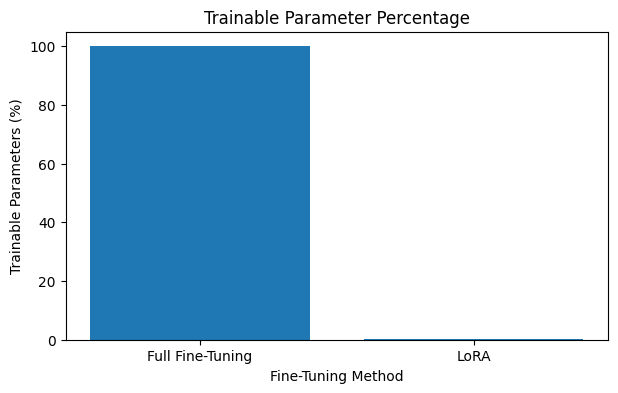

In [24]:
# Visualize the Comparison
# Graph 1: Trainable Parameters
methods = ["Full Fine-Tuning", "LoRA"]
trainable_percentages = [
    full_percentage,
    lora_percentage
]

plt.figure(figsize=(7, 4))
plt.bar(methods, trainable_percentages)
plt.title("Trainable Parameter Percentage")
plt.xlabel("Fine-Tuning Method")
plt.ylabel("Trainable Parameters (%)")
plt.show()

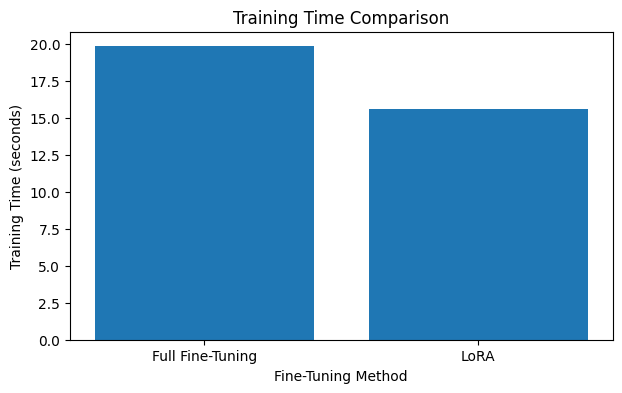

In [25]:
# Graph 2: Training Time
training_times = [
    full_training_time,
    lora_training_time
]

plt.figure(figsize=(7, 4))
plt.bar(methods, training_times)
plt.title("Training Time Comparison")
plt.xlabel("Fine-Tuning Method")
plt.ylabel("Training Time (seconds)")
plt.show()

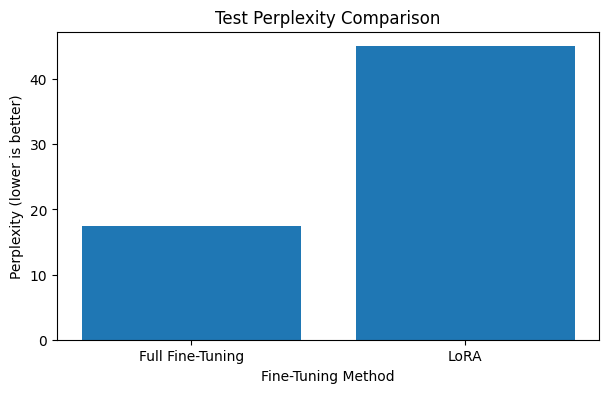

In [26]:
# Graph 3: Test Perplexity
perplexities = [
    full_test_perplexity,
    lora_test_perplexity
]

plt.figure(figsize=(7, 4))
plt.bar(methods, perplexities)
plt.title("Test Perplexity Comparison")
plt.xlabel("Fine-Tuning Method")
plt.ylabel("Perplexity (lower is better)")
plt.show()

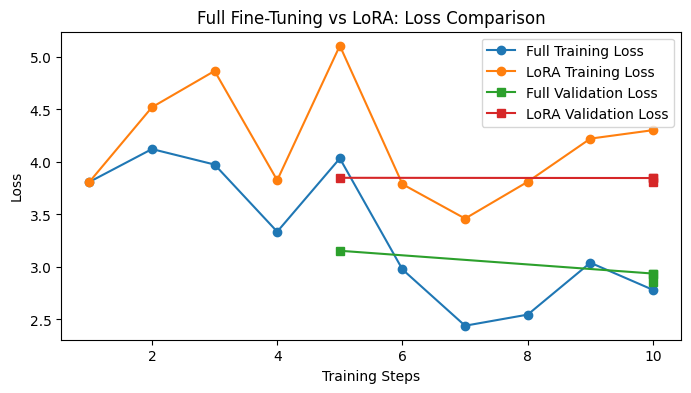

In [27]:
# Graph 4: Training and Validation Loss
lora_logs = lora_trainer.state.log_history

lora_train_steps = []
lora_train_losses = []

lora_eval_steps = []
lora_eval_losses = []

for log in lora_logs:

    if "loss" in log and "eval_loss" not in log:
        lora_train_steps.append(log["step"])
        lora_train_losses.append(log["loss"])

    if "eval_loss" in log:
        lora_eval_steps.append(log["step"])
        lora_eval_losses.append(log["eval_loss"])


plt.figure(figsize=(8, 4))

plt.plot(
    full_train_steps,
    full_train_losses,
    marker="o",
    label="Full Training Loss"
)

plt.plot(
    lora_train_steps,
    lora_train_losses,
    marker="o",
    label="LoRA Training Loss"
)

plt.plot(
    full_eval_steps,
    full_eval_losses,
    marker="s",
    label="Full Validation Loss"
)

plt.plot(
    lora_eval_steps,
    lora_eval_losses,
    marker="s",
    label="LoRA Validation Loss"
)

plt.title("Full Fine-Tuning vs LoRA: Loss Comparison")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [28]:
# Final Experiment Summary
print("========== EXPERIMENT 12 SUMMARY ==========")

print("Student Name: Sayem")
print("Student ID: 25/SET/MTCE/014")

print("\nBase Model:", model_name)
print("Dataset Records:", len(clean_data))
print("Training Samples:", len(train_data))
print("Validation Samples:", len(validation_data))
print("Test Samples:", len(test_data))

print("\nFull Fine-Tuning:")
print("Trainable Parameters:", full_trainable)
print("Trainable Percentage:", round(full_percentage, 4), "%")
print("Training Time:", round(full_training_time, 2), "seconds")
print("Test Perplexity:", round(full_test_perplexity, 4))

print("\nLoRA Fine-Tuning:")
print("Trainable Parameters:", lora_trainable)
print("Trainable Percentage:", round(lora_percentage, 4), "%")
print("Training Time:", round(lora_training_time, 2), "seconds")
print("Test Perplexity:", round(lora_test_perplexity, 4))

print("\nBoth models evaluated on the same test set.")
print("Experiment completed successfully!")

========== EXPERIMENT 12 SUMMARY ==========
Student Name: Sayem
Student ID: 25/SET/MTCE/014

Base Model: distilgpt2
Dataset Records: 20
Training Samples: 14
Validation Samples: 3
Test Samples: 3

Full Fine-Tuning:
Trainable Parameters: 81912576
Trainable Percentage: 100.0 %
Training Time: 19.85 seconds
Test Perplexity: 17.4697

LoRA Fine-Tuning:
Trainable Parameters: 147456
Trainable Percentage: 0.1797 %
Training Time: 15.59 seconds
Test Perplexity: 45.0176

Both models evaluated on the same test set.
Experiment completed successfully!


In [29]:
# Automatic Interpretation
print("\n========== EXPERIMENTAL INTERPRETATION ==========")

if lora_percentage < full_percentage:
    print(
        "1. LoRA trained fewer parameters than Full Fine-Tuning."
    )
else:
    print(
        "1. LoRA did not reduce the trainable parameter percentage."
    )

if lora_checkpoint_size < full_checkpoint_size:
    print(
        "2. LoRA produced a smaller checkpoint."
    )
else:
    print(
        "2. LoRA checkpoint was not smaller in this experiment."
    )

if lora_training_time < full_training_time:
    print(
        "3. LoRA completed training faster in this run."
    )
else:
    print(
        "3. Full Fine-Tuning completed training faster in this run."
    )

if lora_test_perplexity < full_test_perplexity:
    print(
        "4. LoRA achieved lower test perplexity."
    )
elif lora_test_perplexity > full_test_perplexity:
    print(
        "4. Full Fine-Tuning achieved lower test perplexity."
    )
else:
    print(
        "4. Both methods achieved equal test perplexity."
    )

print(
    "\n5. Both methods used the same base model, "
    "dataset split and evaluation test set."
)

print(
    "6. Results are educational because the dataset "
    "and test set are small."
)


========== EXPERIMENTAL INTERPRETATION ==========
1. LoRA trained fewer parameters than Full Fine-Tuning.
2. LoRA produced a smaller checkpoint.
3. LoRA completed training faster in this run.
4. Full Fine-Tuning achieved lower test perplexity.

5. Both methods used the same base model, dataset split and evaluation test set.
6. Results are educational because the dataset and test set are small.


**Observation / Result**

**Observation:**

The experiment compared Full Fine-Tuning and LoRA-based Parameter-Efficient Fine-Tuning using DistilGPT-2. Both methods started from the same pre-trained model and used identical training, validation and test datasets.

Full Fine-Tuning updated all model parameters, whereas LoRA updated only the low-rank adapter parameters. Training time, trainable parameter percentage, checkpoint size, validation loss and test perplexity were recorded.

**Result:**

Both fine-tuning approaches were successfully configured and evaluated using the same unseen test data. The comparison demonstrated the difference in parameter efficiency and the trade-off between computational requirements and language-model performance.

**Interpretation:**

The experimental results demonstrate that LoRA and Full Fine-Tuning have different computational and parameter requirements. Full Fine-Tuning updates all model parameters, whereas LoRA updates only a small fraction of parameters through low-rank adapter matrices.

LoRA is generally more parameter-efficient and produces a smaller adapter checkpoint. However, the best-performing method in terms of test perplexity must be determined from the actual experimental results. A lower test perplexity indicates better language modeling performance on the selected test data.

Therefore, LoRA can be considered an efficient alternative to Full Fine-Tuning when computational resources and storage are limited, provided that its downstream performance is acceptable.